In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl

print("All libraries imported successfully!")

All libraries imported successfully!


# Financial Performance Analysis in Python

## Project Overview

This project analyzes the financial performance of publicly traded companies using Python.

The analysis focuses on revenue, net income, profitability, and year-over-year growth.

### Tools
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

In [2]:
companies = {
    "Apple": "AAPL",
    "Microsoft": "MSFT",
    "Alphabet": "GOOGL"
}

for company, ticker in companies.items():
    print(f"{company}: {ticker}")

Apple: AAPL
Microsoft: MSFT
Alphabet: GOOGL


In [3]:
import requests

url = "https://data.sec.gov/api/xbrl/companyfacts/CIK0000320193.json"

headers = {
    "User-Agent": "Financial Analysis Student student.contact@example.com",
    "Accept-Encoding": "gzip, deflate",
    "Host": "data.sec.gov"
}

response = requests.get(url, headers=headers, timeout=30)

print("Status:", response.status_code)

Status: 200


In [4]:
data = response.json()

print("Company:", data["entityName"])

facts = data["facts"]["us-gaap"]

print("Available financial metrics:", len(facts))

Company: Apple Inc.
Available financial metrics: 512


In [5]:
for key in facts:
    if "Revenue" in key or "NetIncomeLoss" in key:
        print(key)

ContractWithCustomerLiabilityRevenueRecognized
DeferredRevenueCurrent
DeferredRevenueNoncurrent
IncreaseDecreaseInDeferredRevenue
NetIncomeLoss
RevenueFromContractWithCustomerExcludingAssessedTax
Revenues
SalesRevenueNet
SalesRevenueServicesGross


In [6]:
revenue_key = "RevenueFromContractWithCustomerExcludingAssessedTax"

revenue_data = facts[revenue_key]["units"]["USD"]

revenue_df = pd.DataFrame(revenue_data)

print(revenue_df.columns.tolist())

display(revenue_df.tail(10))

['start', 'end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']


,start,end,val,accn,fy,fp,form,filed,frame
110,2025-03-30,2025-06-28,94036000000,0000320193-25-000073,2025,Q3,10-Q,2025-08-01,NaN
111,2025-03-30,2025-06-28,94036000000,0000320193-26-000020,2026,Q3,10-Q,2026-07-31,CY2025Q2
112,2024-09-29,2025-09-27,416161000000,0000320193-25-000079,2025,FY,10-K,2025-10-31,NaN
113,2024-09-29,2025-09-27,416161000000,0000320193-26-000026,2026,FY,10-K,2026-11-03,CY2025
114,2025-09-28,2025-12-27,143756000000,0000320193-26-000006,2026,Q1,10-Q,2026-01-30,CY2025Q4
115,2025-09-28,2026-03-28,254940000000,0000320193-26-000013,2026,Q2,10-Q,2026-05-01,NaN
116,2025-12-28,2026-03-28,111184000000,0000320193-26-000013,2026,Q2,10-Q,2026-05-01,CY2026Q1
117,2025-09-28,2026-06-27,364357000000,0000320193-26-000020,2026,Q3,10-Q,2026-07-31,NaN
118,2026-03-29,2026-06-27,109417000000,0000320193-26-000020,2026,Q3,10-Q,2026-07-31,CY2026Q2
119,2025-09-28,2026-09-26,478834000000,0000320193-26-000026,2026,FY,10-K,2026-11-03,CY2026


In [7]:
#Select annual financial reports
annual_revenue = revenue_df[
    (revenue_df["form"] == "10-K") &
    (revenue_df["fp"] == "FY")
].copy()

#Calculate the reporting period length
annual_revenue["start"] = pd.to_datetime(annual_revenue["start"])
annual_revenue["end"] = pd.to_datetime(annual_revenue["end"])

annual_revenue["days"] = (
    annual_revenue["end"] - annual_revenue["start"]
).dt.days

#Keep full-year observations
annual_revenue = annual_revenue[
    annual_revenue["days"].between(350, 380)
].copy()

#Extract fiscal year from the period end date
annual_revenue["year"] = annual_revenue["end"].dt.year

#Select the latest filing for each fiscal year
annual_revenue = annual_revenue.sort_values("filed")

annual_revenue = annual_revenue.drop_duplicates(
    subset="year",
    keep="last"
)

#Keep years 2020–2025
annual_revenue = annual_revenue[
    annual_revenue["year"].between(2020, 2025)
].copy()

#Convert revenue to billions of USD
annual_revenue["Revenue (USD bn)"] = (
    annual_revenue["val"] / 1_000_000_000
)

display(
    annual_revenue[
        ["year", "Revenue (USD bn)"]
    ].sort_values("year")
)

,year,Revenue (USD bn)
48,2020,274.515
62,2021,365.817
75,2022,394.328
88,2023,383.285
101,2024,391.035
113,2025,416.161


In [8]:
#Sort data by fiscal year
annual_revenue = annual_revenue.sort_values("year").copy()

#Calculate year-over-year revenue growth
annual_revenue["Revenue Growth (%)"] = (
    annual_revenue["Revenue (USD bn)"].pct_change() * 100
)

#Create a clean summary table
revenue_summary = annual_revenue[
    ["year", "Revenue (USD bn)", "Revenue Growth (%)"]
].copy()

display(revenue_summary.round(2))

,year,Revenue (USD bn),Revenue Growth (%)
48,2020,274.52,NaN
62,2021,365.82,33.26
75,2022,394.33,7.79
88,2023,383.28,-2.80
101,2024,391.04,2.02
113,2025,416.16,6.43


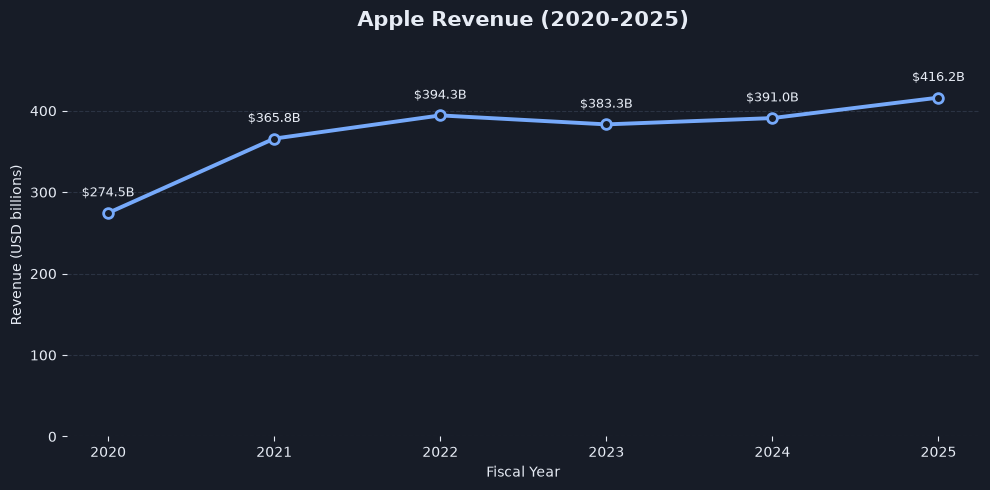

In [9]:

fig, ax = plt.subplots(figsize=(10, 5))

# Dark Analytics colors
background = "#171C27"
text_color = "#E7ECF5"
grid_color = "#394457"
line_color = "#76A9FA"

fig.patch.set_facecolor(background)
ax.set_facecolor(background)

ax.plot(
    revenue_summary["year"],
    revenue_summary["Revenue (USD bn)"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=line_color,
    markerfacecolor=background,
    markeredgecolor=line_color,
    markeredgewidth=2
)

ax.set_title(
    "Apple Revenue (2020-2025)",
    fontsize=15,
    fontweight="bold",
    color=text_color,
    pad=20
)

ax.set_xlabel("Fiscal Year", color=text_color)
ax.set_ylabel("Revenue (USD billions)", color=text_color)

ax.set_xticks(revenue_summary["year"])
ax.tick_params(axis="both", colors=text_color)

ax.grid(
    axis="y",
    linestyle="--",
    color=grid_color,
    alpha=0.6
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

for year, revenue in zip(
    revenue_summary["year"],
    revenue_summary["Revenue (USD bn)"]
):
    ax.annotate(
        f"${revenue:.1f}B",
        (year, revenue),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="normal",
        color=text_color
    )

ax.set_ylim(0, 470)

plt.tight_layout()

plt.savefig(
    "charts/apple_revenue.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


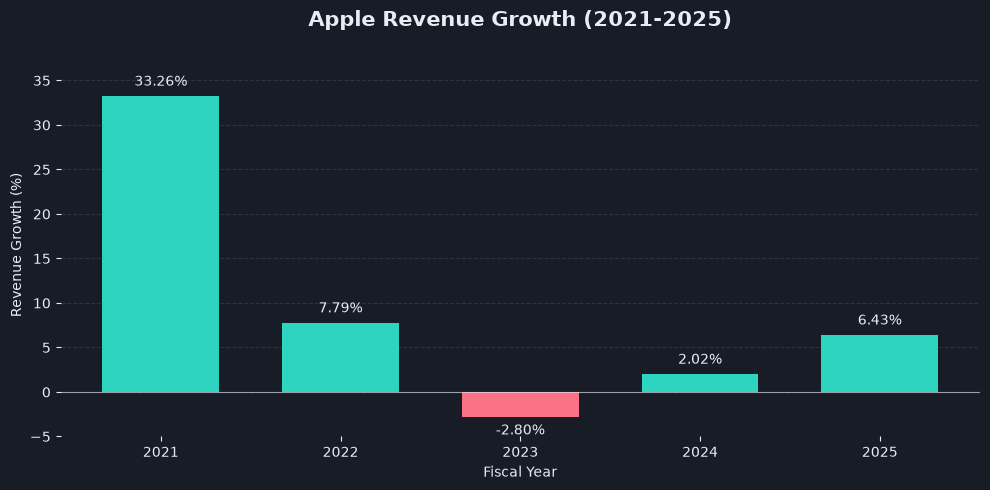

In [10]:

fig, ax = plt.subplots(figsize=(10, 5))

# Dark Analytics colors
background = "#171C27"
text_color = "#E7ECF5"
grid_color = "#394457"
positive_color = "#2DD4BF"
negative_color = "#FB7185"

fig.patch.set_facecolor(background)
ax.set_facecolor(background)

growth_data = revenue_summary.dropna(
    subset=["Revenue Growth (%)"]
)

bars = ax.bar(
    growth_data["year"],
    growth_data["Revenue Growth (%)"],
    width=0.65,
    color=[
        positive_color if value >= 0 else negative_color
        for value in growth_data["Revenue Growth (%)"]
    ]
)

ax.axhline(
    0,
    color=text_color,
    linewidth=0.8,
    alpha=0.6
)

ax.set_title(
    "Apple Revenue Growth (2021-2025)",
    fontsize=15,
    fontweight="bold",
    color=text_color,
    pad=20
)

ax.set_xlabel("Fiscal Year", color=text_color)
ax.set_ylabel("Revenue Growth (%)", color=text_color)

ax.set_xticks(growth_data["year"])
ax.tick_params(axis="both", colors=text_color)

ax.grid(
    axis="y",
    linestyle="--",
    color=grid_color,
    alpha=0.6
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=5,
    fontsize=10,
    color=text_color
)

ax.set_ylim(-5, 38)

plt.tight_layout()

plt.savefig(
    "charts/apple_revenue_growth.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()



In [11]:

net_income_data = facts["NetIncomeLoss"]["units"]["USD"]

net_income_df = pd.DataFrame(net_income_data)

net_income_df["start"] = pd.to_datetime(net_income_df["start"])
net_income_df["end"] = pd.to_datetime(net_income_df["end"])

net_income_df = net_income_df[
    (net_income_df["form"] == "10-K") &
    (net_income_df["fp"] == "FY") &
    (net_income_df["start"].notna()) &
    (net_income_df["end"].notna())
].copy()

net_income_df["duration"] = (
    net_income_df["end"] - net_income_df["start"]
).dt.days

net_income_df = net_income_df[
    net_income_df["duration"].between(330, 380)
]

net_income_df["year"] = net_income_df["end"].dt.year

net_income_summary = (
    net_income_df.sort_values("filed")
    .drop_duplicates(subset="year", keep="last")
    .query("2020 <= year <= 2025")
    [["year", "val"]]
    .sort_values("year")
    .copy()
)

net_income_summary["Net Income (USD bn)"] = (
    net_income_summary["val"] / 1_000_000_000
)

net_income_summary = net_income_summary[
    ["year", "Net Income (USD bn)"]
]

display(net_income_summary.round(2))


,year,Net Income (USD bn)
269,2020,57.41
283,2021,94.68
296,2022,99.80
309,2023,97.00
322,2024,93.74
334,2025,112.01


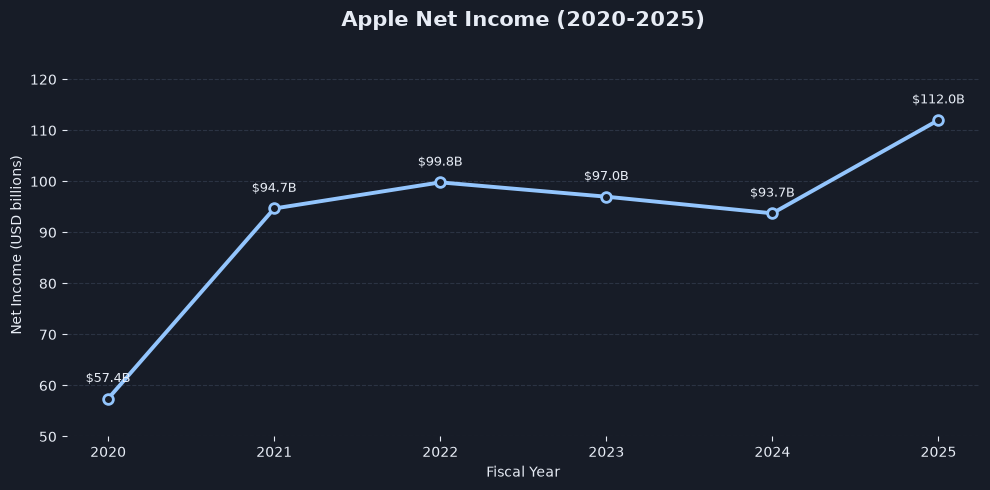

In [12]:

fig, ax = plt.subplots(figsize=(10, 5))

# Dark Analytics colors
background = "#171C27"
text_color = "#E7ECF5"
grid_color = "#394457"
line_color = "#93C5FD"

fig.patch.set_facecolor(background)
ax.set_facecolor(background)

ax.plot(
    net_income_summary["year"],
    net_income_summary["Net Income (USD bn)"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=line_color,
    markerfacecolor=background,
    markeredgecolor=line_color,
    markeredgewidth=2
)

ax.set_title(
    "Apple Net Income (2020-2025)",
    fontsize=15,
    fontweight="bold",
    color=text_color,
    pad=20
)

ax.set_xlabel("Fiscal Year", color=text_color)
ax.set_ylabel("Net Income (USD billions)", color=text_color)

ax.set_xticks(net_income_summary["year"])
ax.tick_params(axis="both", colors=text_color)

ax.grid(
    axis="y",
    linestyle="--",
    color=grid_color,
    alpha=0.6
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

for year, income in zip(
    net_income_summary["year"],
    net_income_summary["Net Income (USD bn)"]
):
    ax.annotate(
        f"${income:.1f}B",
        (year, income),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="normal",
        color=text_color
    )

ax.set_ylim(50, 125)

plt.tight_layout()

plt.savefig(
    "charts/apple_net_income.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


In [13]:

profitability = pd.merge(
    revenue_summary[["year", "Revenue (USD bn)"]],
    net_income_summary,
    on="year",
    how="inner",
    validate="one_to_one"
)

profitability["Net Profit Margin (%)"] = (
    profitability["Net Income (USD bn)"]
    / profitability["Revenue (USD bn)"]
    * 100
)

display(profitability.round(2))


,year,Revenue (USD bn),Net Income (USD bn),Net Profit Margin (%)
0,2020,274.52,57.41,20.91
1,2021,365.82,94.68,25.88
2,2022,394.33,99.80,25.31
3,2023,383.28,97.00,25.31
4,2024,391.04,93.74,23.97
5,2025,416.16,112.01,26.92


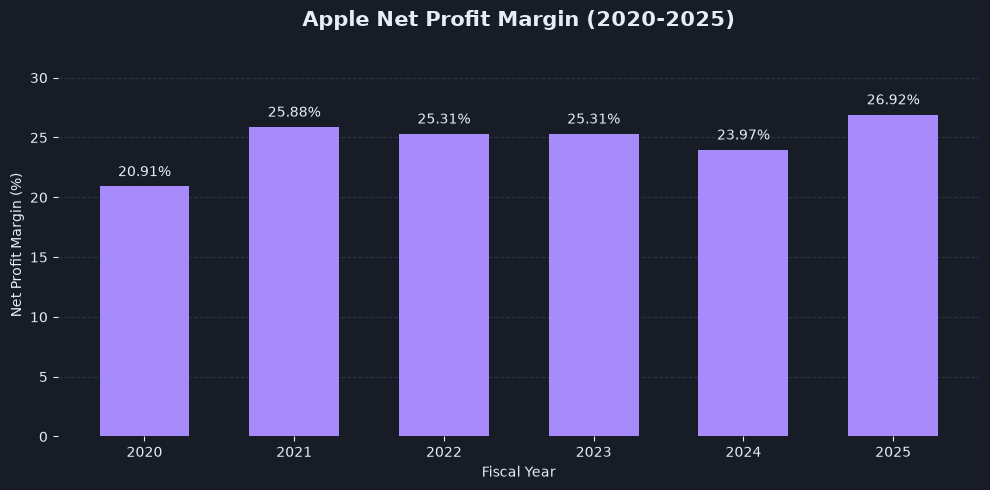

In [14]:

fig, ax = plt.subplots(figsize=(10, 5))

# Dark Analytics colors
background = "#171C27"
text_color = "#E7ECF5"
grid_color = "#394457"
bar_color = "#A78BFA"

fig.patch.set_facecolor(background)
ax.set_facecolor(background)

bars = ax.bar(
    profitability["year"],
    profitability["Net Profit Margin (%)"],
    color=bar_color,
    width=0.6
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=5,
    fontsize=10,
    color=text_color
)

ax.set_title(
    "Apple Net Profit Margin (2020-2025)",
    fontsize=15,
    fontweight="bold",
    color=text_color,
    pad=20
)

ax.set_xlabel("Fiscal Year", color=text_color)
ax.set_ylabel("Net Profit Margin (%)", color=text_color)

ax.set_xticks(profitability["year"])
ax.tick_params(axis="both", colors=text_color)

ax.set_ylim(0, 32)

ax.grid(
    axis="y",
    linestyle="--",
    color=grid_color,
    alpha=0.6
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()

plt.savefig(
    "charts/apple_net_profit_margin.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()




## Financial Insights

### 1. Revenue Performance
Apple's revenue increased from $274.5 billion in 2020 to $416.2 billion in 2025, representing approximately 51.6% total growth.

The strongest annual revenue growth occurred in 2021 (+33.26%). Revenue declined by 2.80% in 2023 before returning to positive growth in 2024 and 2025.

### 2. Net Income
Net income increased from $57.4 billion in 2020 to $112.0 billion in 2025, nearly doubling over the period.

Despite revenue growth in 2024, net income declined, indicating that higher sales did not translate into higher profitability that year.

### 3. Profitability
Apple's net profit margin increased from 20.91% in 2020 to 26.92% in 2025.

The margin declined to 23.97% in 2024 before recovering to its highest level in the analyzed period in 2025.

### 4. Key Takeaway
Between 2020 and 2025, Apple's net income grew faster than its revenue, resulting in an overall improvement in net profit margin.

However, the decline in profitability in 2024 shows that revenue growth alone does not guarantee higher profits.


In [15]:

#Data Validation

print("DATA VALIDATION REPORT")
print("-" * 40)

#Check missing values
print("\nMissing values:")
print(profitability.isnull().sum())

#Check duplicate years
print("\nDuplicate years:")
print(profitability["year"].duplicated().sum())

#Check number of years
print("\nNumber of years:")
print(len(profitability))

#Check expected years
expected_years = set(range(2020, 2026))
actual_years = set(profitability["year"])

print("\nMissing years:")
print(sorted(expected_years - actual_years))

#Check financial values
print("\nNegative revenue values:")
print((profitability["Revenue (USD bn)"] < 0).sum())

print("\nNegative net income values:")
print((profitability["Net Income (USD bn)"] < 0).sum())


DATA VALIDATION REPORT
----------------------------------------

Missing values:
year                     0
Revenue (USD bn)         0
Net Income (USD bn)      0
Net Profit Margin (%)    0
dtype: int64

Duplicate years:
0

Number of years:
6

Missing years:
[]

Negative revenue values:
0

Negative net income values:
0


In [16]:

#Verify SEC reporting periods

def check_reporting_periods(df, metric_name):
    result = df.copy()

    result["start"] = pd.to_datetime(result["start"])
    result["end"] = pd.to_datetime(result["end"])

    result["year"] = result["end"].dt.year
    result["duration"] = (
        result["end"] - result["start"]
    ).dt.days

    result = result[
        (result["year"].between(2020, 2025)) &
        (result["form"] == "10-K") &
        (result["fp"] == "FY") &
        (result["duration"].between(330, 380))
    ].copy()

    result = (
        result.sort_values("filed")
        .drop_duplicates(subset="year", keep="last")
        .sort_values("year")
    )

    print(f"\n{metric_name} - SEC Reporting Periods")

    display(
        result[
            ["year", "start", "end", "fy", "fp", "form", "filed", "accn"]
        ].reset_index(drop=True)
    )

check_reporting_periods(revenue_df, "Revenue")
check_reporting_periods(net_income_df, "Net Income")




Revenue - SEC Reporting Periods


,year,start,end,fy,fp,form,filed,accn
0,2020,2019-09-29,2020-09-26,2022,FY,10-K,2022-10-28,0000320193-22-000108
1,2021,2020-09-27,2021-09-25,2023,FY,10-K,2023-11-03,0000320193-23-000106
2,2022,2021-09-26,2022-09-24,2024,FY,10-K,2024-11-01,0000320193-24-000123
3,2023,2022-09-25,2023-09-30,2025,FY,10-K,2025-10-31,0000320193-25-000079
4,2024,2023-10-01,2024-09-28,2026,FY,10-K,2026-11-03,0000320193-26-000026
5,2025,2024-09-29,2025-09-27,2026,FY,10-K,2026-11-03,0000320193-26-000026



Net Income - SEC Reporting Periods


,year,start,end,fy,fp,form,filed,accn
0,2020,2019-09-29,2020-09-26,2022.0,FY,10-K,2022-10-28,0000320193-22-000108
1,2021,2020-09-27,2021-09-25,2023.0,FY,10-K,2023-11-03,0000320193-23-000106
2,2022,2021-09-26,2022-09-24,2024.0,FY,10-K,2024-11-01,0000320193-24-000123
3,2023,2022-09-25,2023-09-30,2025.0,FY,10-K,2025-10-31,0000320193-25-000079
4,2024,2023-10-01,2024-09-28,2026.0,FY,10-K,2026-11-03,0000320193-26-000026
5,2025,2024-09-29,2025-09-27,2026.0,FY,10-K,2026-11-03,0000320193-26-000026


In [17]:

#Check original annual SEC filings

def original_annual_filings(df):
    result = df.copy()

    result["start"] = pd.to_datetime(result["start"])
    result["end"] = pd.to_datetime(result["end"])

    result["year"] = result["end"].dt.year
    result["duration"] = (
        result["end"] - result["start"]
    ).dt.days

    result = result[
        (result["year"].between(2020, 2025)) &
        (result["form"] == "10-K") &
        (result["fp"] == "FY") &
        (result["duration"].between(330, 380)) &
        (result["fy"] == result["year"])
    ].copy()

    result = (
        result.sort_values("filed")
        .drop_duplicates("year", keep="last")
        .sort_values("year")
    )

    return result

revenue_original = original_annual_filings(revenue_df)
income_original = original_annual_filings(net_income_df)

print("Revenue - Original Filings")
display(revenue_original[["year", "val", "fy", "filed"]])

print("Net Income - Original Filings")
display(income_original[["year", "val", "fy", "filed"]])


Revenue - Original Filings


,year,val,fy,filed
46,2020,274515000000,2020,2020-10-30
60,2021,365817000000,2021,2021-10-29
73,2022,394328000000,2022,2022-10-28
86,2023,383285000000,2023,2023-11-03
99,2024,391035000000,2024,2024-11-01
112,2025,416161000000,2025,2025-10-31


Net Income - Original Filings


,year,val,fy,filed
267,2020,57411000000,2020.0,2020-10-30
281,2021,94680000000,2021.0,2021-10-29
294,2022,99803000000,2022.0,2022-10-28
307,2023,96995000000,2023.0,2023-11-03
320,2024,93736000000,2024.0,2024-11-01
333,2025,112010000000,2025.0,2025-10-31


In [18]:

#Create the final financial dataset

revenue_final = revenue_original[["year", "val"]].copy()
revenue_final = revenue_final.rename(
    columns={"val": "Revenue (USD bn)"}
)

income_final = income_original[["year", "val"]].copy()
income_final = income_final.rename(
    columns={"val": "Net Income (USD bn)"}
)

#Combine revenue and net income
financial_final = pd.merge(
    revenue_final,
    income_final,
    on="year",
    how="inner",
    validate="one_to_one"
)

#Convert USD to billions
financial_final["Revenue (USD bn)"] /= 1_000_000_000
financial_final["Net Income (USD bn)"] /= 1_000_000_000

#Calculate financial indicators
financial_final["Revenue Growth (%)"] = (
    financial_final["Revenue (USD bn)"].pct_change() * 100
)

financial_final["Net Profit Margin (%)"] = (
    financial_final["Net Income (USD bn)"]
    / financial_final["Revenue (USD bn)"] * 100
)

financial_final = financial_final.sort_values("year").reset_index(drop=True)

display(financial_final.round(2))


,year,Revenue (USD bn),Net Income (USD bn),Revenue Growth (%),Net Profit Margin (%)
0,2020,274.52,57.41,NaN,20.91
1,2021,365.82,94.68,33.26,25.88
2,2022,394.33,99.80,7.79,25.31
3,2023,383.28,97.00,-2.80,25.31
4,2024,391.04,93.74,2.02,23.97
5,2025,416.16,112.01,6.43,26.92


In [19]:

from pathlib import Path

#Create a folder for processed data
output_dir = Path("data")
output_dir.mkdir(exist_ok=True)

#Export final financial dataset
financial_final.to_excel(
    output_dir / "apple_financial_analysis.xlsx",
    index=False
)

financial_final.to_csv(
    output_dir / "apple_financial_analysis.csv",
    index=False
)

print("Financial data exported successfully!")


Financial data exported successfully!


## Financial Insights

### 1. Revenue Growth
Apple's revenue increased from $274.52 billion in 2020 to $416.16 billion in 2025, representing approximately 51.6% total growth.

The strongest annual revenue growth occurred in 2021 (+33.26%), while 2023 was the only year with a decline (-2.80%).

### 2. Net Income
Apple's net income increased from $57.41 billion in 2020 to $112.01 billion in 2025.

Despite a decline in net income during 2023–2024, the company recorded its highest net income in 2025.

### 3. Profitability
Apple's net profit margin increased from 20.91% in 2020 to 26.92% in 2025.

In 2025, the company achieved its highest net profit margin within the analyzed period, indicating improved profitability relative to revenue.

### 4. Key Takeaway
Between 2020 and 2025, Apple demonstrated strong revenue growth and improved profitability. Although financial performance fluctuated in certain years, the company ended the period with its highest revenue, net income, and net profit margin.

## 5. Business Insights

### Revenue Growth and Volatility

Apple's revenue increased from $274.52 billion in 2020 to $416.16 billion in 2025, representing cumulative growth of approximately 51.6%.

However, revenue growth was not consistent throughout the period. Following a significant increase of 33.26% in 2021, growth slowed to 7.79% in 2022 and turned negative in 2023 (-2.80%). Revenue subsequently recovered, growing by 2.02% in 2024 and 6.43% in 2025.

These fluctuations highlight the importance of examining year-over-year growth rather than relying solely on cumulative performance.

### Profitability vs. Revenue

Apple's net profit margin increased from 20.91% in 2020 to 26.92% in 2025, an improvement of 6.01 percentage points.

In 2025, revenue increased by approximately 6.43%, while net income grew by approximately 19.5% compared with 2024.

Net income therefore grew substantially faster than revenue, resulting in an improvement in net profit margin from 23.97% in 2024 to 26.92% in 2025.

This demonstrates that revenue growth and profitability do not necessarily move at the same rate.

### Business Implications

The analysis highlights three key observations:

- **Revenue growth alone does not fully describe financial performance.** A company may increase its revenue without achieving a proportional improvement in profitability.
- **Net profit margin provides additional insight into financial performance.** Evaluating profitability alongside revenue helps identify whether sales growth translates into stronger earnings.
- **Combining multiple financial indicators supports a more comprehensive assessment.** Revenue, net income, annual growth rates, and profit margins provide complementary perspectives on business performance.

### Limitations

This analysis focuses on Apple's annual revenue and net income figures for fiscal years 2020–2025.

It does not include a detailed examination of operating expenses, product-level performance, geographic segments, cash flows, or macroeconomic factors.

Consequently, the analysis identifies financial trends and changes in profitability but does not establish the underlying causes of these changes.

### Key Takeaway

Between 2020 and 2025, Apple demonstrated substantial revenue growth and improved overall profitability despite fluctuations in annual performance.

In 2025, the company achieved its highest revenue, net income, and net profit margin within the analyzed period.

The findings emphasize the importance of evaluating growth and profitability together when assessing a company's financial performance.

In [2]:

#Final financial data verification

print("FINANCIAL DATA SUMMARY")
print("-" * 45)

display(financial_final.round(2))

print("\nRevenue growth check:")
calculated_growth = (
    financial_final["Revenue (USD bn)"].pct_change() * 100
)

print(
    "Growth calculations correct:",
    calculated_growth.round(2).equals(
        financial_final["Revenue Growth (%)"].round(2)
    )
)

print("\nNet profit margin check:")
calculated_margin = (
    financial_final["Net Income (USD bn)"]
    / financial_final["Revenue (USD bn)"] * 100
)

print(
    "Margin calculations correct:",
    calculated_margin.round(2).equals(
        financial_final["Net Profit Margin (%)"].round(2)
    )
)


FINANCIAL DATA SUMMARY
---------------------------------------------


NameError: name 'financial_final' is not defined

In [ ]:


#Check original SEC reporting periods

columns_to_check = [
    "start", "end", "fy", "fp", "form", "filed"
]

print("REVENUE - SEC REPORTING PERIODS")
display(revenue_df[columns_to_check].tail(15))

print("\nNET INCOME - SEC REPORTING PERIODS")
display(net_income_df[columns_to_check].tail(15))



REVENUE - SEC REPORTING PERIODS


,start,end,fy,fp,form,filed
105,2024-09-29,2025-03-29,2026,Q2,10-Q,2026-05-01
106,2024-12-29,2025-03-29,2025,Q2,10-Q,2025-05-02
107,2024-12-29,2025-03-29,2026,Q2,10-Q,2026-05-01
108,2024-09-29,2025-06-28,2025,Q3,10-Q,2025-08-01
109,2024-09-29,2025-06-28,2026,Q3,10-Q,2026-07-31
110,2025-03-30,2025-06-28,2025,Q3,10-Q,2025-08-01
111,2025-03-30,2025-06-28,2026,Q3,10-Q,2026-07-31
112,2024-09-29,2025-09-27,2025,FY,10-K,2025-10-31
113,2024-09-29,2025-09-27,2026,FY,10-K,2026-11-03
114,2025-09-28,2025-12-27,2026,Q1,10-Q,2026-01-30



NET INCOME - SEC REPORTING PERIODS


,start,end,fy,fp,form,filed
281,2020-09-27,2021-09-25,2021.0,FY,10-K,2021-10-29
282,2020-09-27,2021-09-25,2022.0,FY,10-K,2022-10-28
283,2020-09-27,2021-09-25,2023.0,FY,10-K,2023-11-03
294,2021-09-26,2022-09-24,2022.0,FY,10-K,2022-10-28
295,2021-09-26,2022-09-24,2023.0,FY,10-K,2023-11-03
296,2021-09-26,2022-09-24,2024.0,FY,10-K,2024-11-01
307,2022-09-25,2023-09-30,2023.0,FY,10-K,2023-11-03
308,2022-09-25,2023-09-30,2024.0,FY,10-K,2024-11-01
309,2022-09-25,2023-09-30,2025.0,FY,10-K,2025-10-31
320,2023-10-01,2024-09-28,2024.0,FY,10-K,2024-11-01


In [ ]:

#Final SEC data consistency check

expected_revenue = [
    274.515, 365.817, 394.328,
    383.285, 391.035, 416.161
]

expected_net_income = [
    57.411, 94.680, 99.803,
    96.995, 93.736, 112.010
]

expected_years = list(range(2020, 2026))

years_match = (
    financial_final["year"].tolist() == expected_years
)

revenue_match = all(
    abs(a - b) < 0.0001
    for a, b in zip(
        financial_final["Revenue (USD bn)"],
        expected_revenue
    )
)

income_match = all(
    abs(a - b) < 0.0001
    for a, b in zip(
        financial_final["Net Income (USD bn)"],
        expected_net_income
    )
)

print("Fiscal years correct:", years_match)
print("Revenue matches SEC filings:", revenue_match)
print("Net income matches SEC filings:", income_match)


Fiscal years correct: True
Revenue matches SEC filings: True
Net income matches SEC filings: True
